<a href="https://colab.research.google.com/github/databyhuseyn/MachineLearning/blob/main/Imbalance_Dataset_Handling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [97]:
#!/bin/bash
!kaggle datasets download soheiltehranipour/it-customer-churn

Dataset URL: https://www.kaggle.com/datasets/soheiltehranipour/it-customer-churn
License(s): CC0-1.0
it-customer-churn.zip: Skipping, found more recently modified local copy (use --force to force download)


In [98]:
!ls

IT_customer_churn.csv  it-customer-churn.zip  sample_data


In [99]:
from zipfile import ZipFile

In [100]:
with ZipFile('it-customer-churn.zip', 'r') as f:
  f.extractall()

In [101]:
!ls

IT_customer_churn.csv  it-customer-churn.zip  sample_data


In [102]:
import pandas as pd

In [120]:
df = pd.read_csv('IT_customer_churn.csv')

In [121]:
df.head(1)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No


In [122]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'].str.replace(' ', ''))

In [123]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   object 
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   object 
 3   Dependents        7043 non-null   object 
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   object 
 6   MultipleLines     7043 non-null   object 
 7   InternetService   7043 non-null   object 
 8   OnlineSecurity    7043 non-null   object 
 9   OnlineBackup      7043 non-null   object 
 10  DeviceProtection  7043 non-null   object 
 11  TechSupport       7043 non-null   object 
 12  StreamingTV       7043 non-null   object 
 13  StreamingMovies   7043 non-null   object 
 14  Contract          7043 non-null   object 
 15  PaperlessBilling  7043 non-null   object 
 16  PaymentMethod     7043 non-null   object 


In [124]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7032.000000
mean,0.162147,32.371149,64.761692,2283.300441
std,0.368612,24.559481,30.090047,2266.771362
min,0.000000,0.000000,18.250000,18.800000
25%,0.000000,9.000000,35.500000,401.450000
50%,0.000000,29.000000,70.350000,1397.475000
75%,0.000000,55.000000,89.850000,3794.737500
max,1.000000,72.000000,118.750000,8684.800000


<Axes: >

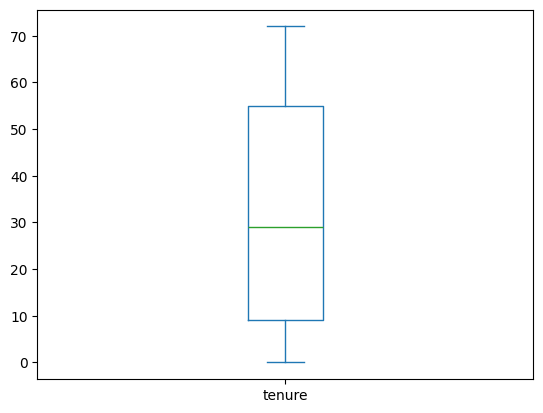

In [125]:
df['tenure'].plot(kind='box')

In [126]:
df.isna().sum()

,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0
OnlineBackup,0


In [127]:
df['Churn'].value_counts()

,count
Churn,
No,5174
Yes,1869


<Axes: ylabel='count'>

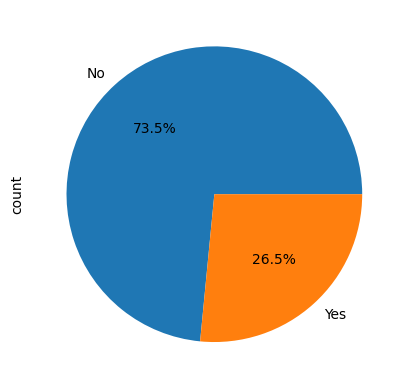

In [128]:
df['Churn'].value_counts().plot(kind='pie', autopct='%1.1f%%')

In [129]:
import numpy as np

In [130]:
no_churn_df = df[df['Churn'] == 'No']
yes_churn_df = df[df['Churn'] == 'Yes']

In [131]:
no_churn_df = no_churn_df.iloc[np.random.permutation(len(no_churn_df))][:len(df) - len(no_churn_df)]

In [132]:
merged_undersampled_df = pd.concat([no_churn_df, yes_churn_df])

In [133]:
merged_undersampled_df = merged_undersampled_df.iloc[np.random.permutation(len(merged_undersampled_df))]

In [161]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score

In [135]:
X_undersampled = merged_undersampled_df.drop(['Churn'], axis=1)
y_undersampled = merged_undersampled_df['Churn'].copy()

In [139]:
len(y_undersampled)

3738

In [141]:
X_train_undersampled, X_test_undersampled, y_train_undersampled, y_test_undersampled =  train_test_split(X_undersampled, y_undersampled, test_size=0.2, stratify=y_undersampled)

In [167]:
def train(X_train, y_train, X_test, y_test, model):

  num_features = X_train.select_dtypes(include='number').columns
  cat_features = X_train.select_dtypes(exclude='number').columns

  num_pipeline = Pipeline([
      ('impute', SimpleImputer(strategy='median')),
      ('scale', StandardScaler())
  ])

  cat_pipeline = Pipeline([
      ('impute', SimpleImputer(strategy='most_frequent')),
      ('encode', OneHotEncoder(handle_unknown='ignore'))
  ])

  transformer = ColumnTransformer([
      ('num', num_pipeline, num_features),
      ('cat', cat_pipeline, cat_features)
  ], remainder='passthrough')

  full_pipeline = Pipeline([
      ('preprocessing', transformer),
      ('estimator', model)
  ])

  full_pipeline.fit(X_train, y_train)
  train_preds, test_preds = full_pipeline.predict(X_train), full_pipeline.predict(X_test)
  tr_f1_score = f1_score(train_preds, y_train, average='macro')
  te_f1_score = f1_score(test_preds, y_test, average='macro')

  print(f'Train Score: {full_pipeline.score(X_train, y_train)}\nTest Score: {full_pipeline.score(X_test, y_test)}')
  print(f'Train F1 Score: {tr_f1_score}\nTest F1 Score: {te_f1_score}')

  return full_pipeline

In [168]:
rfc = RandomForestClassifier()

In [169]:
from sklearn.linear_model import LogisticRegression

In [170]:
lr = LogisticRegression()

In [177]:
fp = train(X_train_undersampled, y_train_undersampled, X_test_undersampled, y_test_undersampled, rfc)

Train Score: 0.9976588628762542
Test Score: 0.7486631016042781
Train F1 Score: 0.997658862614385
Test F1 Score: 0.7486613047363717


In [178]:
from imblearn.over_sampling import SMOTE

In [179]:
X = df.drop(['Churn'],axis=1)
y = df['Churn'].copy()

In [180]:
X_train, X_test, y_train, y_test =  train_test_split(X, y, test_size=0.2, stratify=y)

In [181]:
def train_with_smote(X_train, y_train, X_test, y_test, model):

  sm = SMOTE(sampling_strategy='minority')

  num_features = X_train.select_dtypes(include='number').columns
  cat_features = X_train.select_dtypes(exclude='number').columns

  num_pipeline = Pipeline([
      ('impute', SimpleImputer(strategy='median')),
      ('scale', StandardScaler())
  ])

  cat_pipeline = Pipeline([
      ('impute', SimpleImputer(strategy='most_frequent')),
      ('encode', OneHotEncoder(handle_unknown='ignore'))
  ])

  transformer = ColumnTransformer([
      ('num', num_pipeline, num_features),
      ('cat', cat_pipeline, cat_features)
  ], remainder='passthrough')

  X_train = transformer.fit_transform(X_train)
  X_test = transformer.transform(X_test)

  X_train, y_train = sm.fit_resample(X_train, y_train)


  model.fit(X_train, y_train)

  train_preds, test_preds = model.predict(X_train), model.predict(X_test)
  tr_f1_score = f1_score(train_preds, y_train, average='macro')
  te_f1_score = f1_score(test_preds, y_test, average='macro')

  print(f'Train Score: {model.score(X_train, y_train)}\nTest Score: {model.score(X_test, y_test)}')
  print(f'Train F1 Score: {tr_f1_score}\nTest F1 Score: {te_f1_score}')

  return model

In [182]:
fp_smote = train_with_smote(X_train_undersampled, y_train_undersampled, X_test_undersampled, y_test_undersampled, rfc)

Train Score: 0.9976588628762542
Test Score: 0.7419786096256684
Train F1 Score: 0.9976588500445915
Test F1 Score: 0.7419412501809901


In [188]:
def train_plain(X_train, y_train, X_test, y_test, model):

  num_features = X_train.select_dtypes(include='number').columns
  cat_features = X_train.select_dtypes(exclude='number').columns

  num_pipeline = Pipeline([
      ('impute', SimpleImputer(strategy='median')),
      ('scale', StandardScaler())
  ])

  cat_pipeline = Pipeline([
      ('impute', SimpleImputer(strategy='most_frequent')),
      ('encode', OneHotEncoder(handle_unknown='ignore'))
  ])

  transformer = ColumnTransformer([
      ('num', num_pipeline, num_features),
      ('cat', cat_pipeline, cat_features)
  ], remainder='passthrough')

  full_pipeline = Pipeline([
      ('preprocessing', transformer),
      ('estimator', model)
  ])

  full_pipeline.fit(X_train, y_train)
  train_preds, test_preds = full_pipeline.predict(X_train), full_pipeline.predict(X_test)
  tr_f1_score = f1_score(train_preds, y_train, average='macro')
  te_f1_score = f1_score(test_preds, y_test, average='macro')

  print(f'Train Score: {full_pipeline.score(X_train, y_train)}\nTest Score: {full_pipeline.score(X_test, y_test)}')
  print(f'Train F1 Score: {tr_f1_score}\nTest F1 Score: {te_f1_score}')

  return full_pipeline

In [189]:
fp = train_plain(X_train, y_train, X_test, y_test, rfc)

Train Score: 0.9976925807596734
Test Score: 0.7906316536550745
Train F1 Score: 0.9970402406763359
Test F1 Score: 0.7066168348314646
